# Script to parse jedi files

In [2]:
import glob
import numpy as np
import pandas as pd
import datetime as dt

import matplotlib.pyplot as plt 
import matplotlib.colors as colors
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection

from JunoPy.jedi import JediChannel, JediData
from JunoPy.index import IndexFile

In [9]:
startevent = dt.datetime.strptime('2017-236T20:21:15', '%Y-%jT%H:%M:%S')
endevent   = dt.datetime.strptime('2017-236T20:21:38', '%Y-%jT%H:%M:%S')
start = startevent - dt.timedelta(minutes=30)
end   = endevent + dt.timedelta(minutes=30)

jedifiles = glob.glob('data/jedi/*SISP_CDR_{:s}_*.TAB'.format(start.strftime('%Y%j')))
if not jedifiles:
    jediindex = IndexFile(dataset='jedi')
    jediindex.get_files_between_dates(
        start, end, DoDownload=True, sid='ERSISP')
    
jedidatas = []
for jedifile in jedifiles:
    jedidatas.append(JediData(filename=jedifile))
    print(jedifile)
    
jedidata = jedidatas[0]
jedidata.df = jedidata.df.loc[start:end]

data/jedi/JED_270_LOERSISP_CDR_2017236_V03.TAB
data/jedi/JED_180_LOERSISP_CDR_2017236_V03.TAB


In [10]:
jedidata.df.head()

,UTC,ETStart,ETLookDirection,ETEnd,Duration,SectorDeadTime,LargePixel,SCLKStart,SCLKLookDirection,SCLKEnd,...,Pitch_Angle_T4,Pitch_Angle_T5,SSD0 Counts,SSD1 Counts,SSD2 Counts,SSD3 Counts,SSD4 Counts,SSD5 Counts,Valid Events Processed,Valid Energy Events
time,,,,,,,,,,,,,,,,,,,,,
2017-08-24 19:51:46,2017-08-24T19:51:46,5.568763e+08,5.568764e+08,5.568764e+08,2.513708,0.079,true,5/0556876490:60293,5/0556876522:22340,5/0556876553:49971,...,49.334076,67.588960,3.978186,9.945466,7.160735,6.365098,9.945466,7.160735,42.964412,42.964412
2017-08-24 19:51:48,2017-08-24T19:51:48,5.568763e+08,5.568764e+08,5.568764e+08,2.513708,0.079,true,5/0556876493:28421,5/0556876524:56009,5/0556876556:18088,...,65.176520,86.592603,9.945466,10.741103,5.967279,9.149828,7.956373,7.558554,48.533873,48.533873
2017-08-24 19:51:51,2017-08-24T19:51:51,5.568763e+08,5.568764e+08,5.568764e+08,2.513708,0.079,true,5/0556876495:62085,5/0556876527:24142,5/0556876558:51741,...,84.656720,106.504968,11.934559,7.160735,9.149828,7.956373,9.149828,7.956373,52.512059,52.512059
2017-08-24 19:51:53,2017-08-24T19:51:53,5.568764e+08,5.568764e+08,5.568764e+08,2.513708,0.079,true,5/0556876498:30213,5/0556876529:57812,5/0556876561:19858,...,104.915529,124.652715,9.547647,8.752010,6.762917,5.171642,6.365098,5.967279,42.168775,42.168775
2017-08-24 19:51:56,2017-08-24T19:51:56,5.568764e+08,5.568764e+08,5.568764e+08,2.513708,0.079,true,5/0556876500:63876,5/0556876532:25945,5/0556876563:53511,...,121.403633,134.835852,5.967279,8.354191,11.138922,8.354191,9.547647,3.978186,42.964412,42.964412


##  Create the spectrogram data we need
X - time  
Y - frequency bins  
C - flux added from each look direction  

(15, 720)
(15, 720)
(15, 720)
(15, 720)
(15, 720)
(15, 720)


/Users/sarkango/.virtualenvs/JunoPy/lib/python3.7/site-packages/matplotlib-3.2.1-py3.7-macosx-10.14-x86_64.egg/matplotlib/colors.py:1171: RuntimeWarning: invalid value encountered in less_equal
  mask |= resdat <= 0


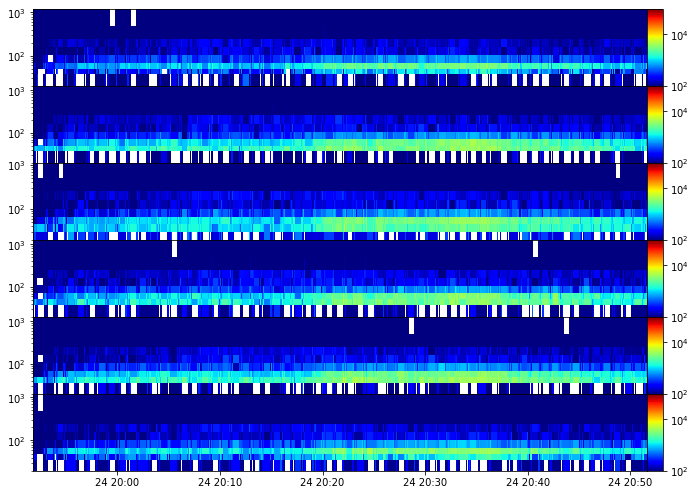

In [11]:


df = jedidata.df
df['endtime'] = df.apply(lambda x: x.name + dt.timedelta(seconds=x['Duration']), axis=1)

x = np.zeros(len(df) + 1, dtype=object)
x[:-1] = df.index
x[-1] = df['endtime'][-1]
    
fig, ax = plt.subplots(6, 1, sharex=True, figsize=(11, 8.5), gridspec_kw=dict(hspace=0))

for iax, a in enumerate(ax):

    columns = [x for x in jedidata.FluxChannels.columns if 'T{:d}'.format(iax) in x]
    freq_lower = jedidata.FluxChannels.lowE[iax * len(columns): (iax + 1) * len(columns)]
    freq_upper = jedidata.FluxChannels.highE[iax * len(columns): (iax + 1) * len(columns)]
    
    y = np.zeros(len(freq_lower) * 2)
    j = 0
    for k in range(len(freq_lower)):
        y[j] = float(freq_lower[k])
        y[j + 1] = float(freq_upper[k])
        j += 2

    c0 = df[columns].values.T
    c = np.zeros((y.shape[0] - 1, x.shape[0] - 1))
    for i in range(c.shape[0]):
        for j in range(c.shape[1]):
            if i % 2 != 0:
                c[i, j] = np.NaN
            else:
                c[i, j] = c0[int(i/2), j]
    print(c.shape)


    mp = a.pcolormesh(x, y, c, cmap='jet', norm=colors.LogNorm(), vmin=100, vmax=10**5)
    a.set_yscale('log')
    a.set_ylim([20, y[-1]])

    size = 0.02
    bbox = a.get_position()
    cax = a.figure.add_axes([bbox.x1, bbox.y0, 0.02, bbox.y1- bbox.y0])
    cbar = a.figure.colorbar(mp, cax=cax)
    a.label_outer()
        
plt.show()

In [12]:
y

array([  19.  ,   34.95,   36.15,   48.09,   49.09,   67.9 ,   68.79,
        101.68,  102.49,  156.39,  157.13,  247.43,  248.1 ,  471.29,
        471.92, 1188.4 ])

## 3. Plot the pitch angle spectrogram. 

In [13]:

# Calculate the pitch angle - 
# Integrate the energy flux in the channel. 

df = jedidata.df
df['endtime'] = df.apply(lambda x: x.name + dt.timedelta(seconds=x['Duration']), axis=1)

def calc_broadband_flux(x, lowE, upE):
    sum = 0
    for i, val in enumerate(x.values):
        if val > 0:
            sum += val * (float(upE[i]) - float(lowE[i]))
    return sum
    
for iax in range(6):
    columns = [x for x in jedidata.FluxChannels.columns if 'T{:d}'.format(iax) in x]
    freq_lower = jedidata.FluxChannels.lowE[iax * len(columns): (iax + 1) * len(columns)]
    freq_upper = jedidata.FluxChannels.highE[iax * len(columns): (iax + 1) * len(columns)]

    df['BroadbandFlux_T{:d}'.format(iax)] = df.apply(
        lambda x: calc_broadband_flux(
            x[columns], freq_lower, freq_upper), axis=1)


        

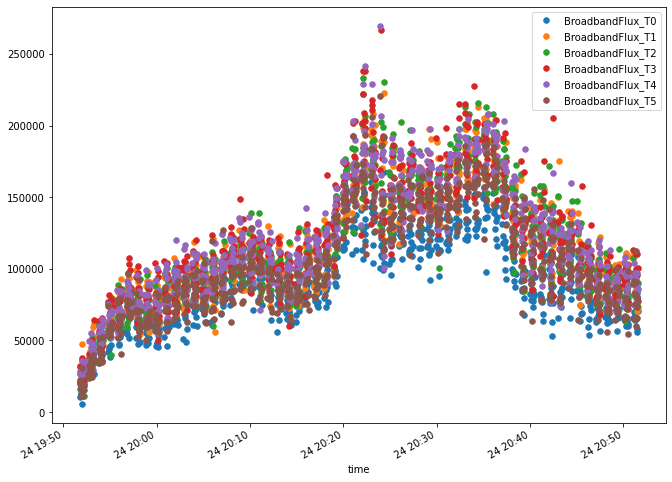

In [15]:
# for iax in range(6):
    # df['BroadbandFlux_T{:d}'.format(iax)].plot(logy=True, figsize=(11, 8.5), legend=True, lw=1.0, ls='dotted')
df.plot(y=['BroadbandFlux_T{:d}'.format(iax) for iax in range(6)], figsize=(11,8.5), legend=True, markersize=11., style='.')

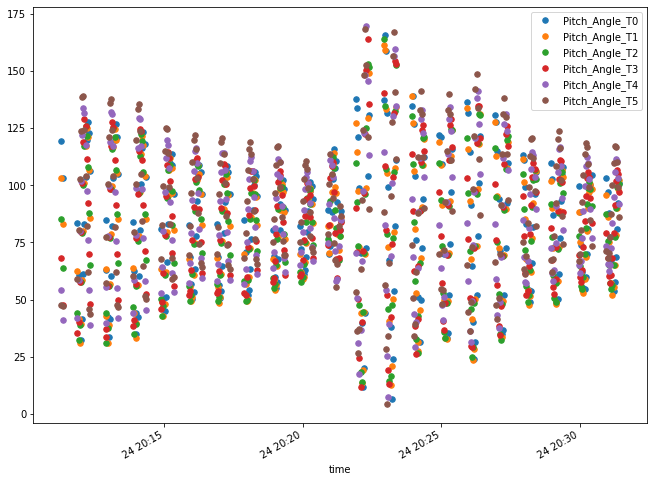

In [49]:
df.plot(y=['Pitch_Angle_T{:d}'.format(iax) for iax in range(6)], figsize=(11,8.5), legend=True, markersize=11., style='.')

## Multiple JEDI files (090-180-270) and making the pitch angle versus time spectra. 

In [ ]:
start = dt.datetime.strptime('2019-089T20:35:40', '%Y-%jT%H:%M:%S') - dt.timedelta(minutes=5)
end   = dt.datetime.strptime('2019-089T20:36:36', '%Y-%jT%H:%M:%S') + dt.timedelta(minutes=5)

jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))

